In [ ]:

# STEP 1: Install required libraries

!pip -q install pandas numpy matplotlib seaborn scikit-learn plotly joblib openpyxl

print("All libraries installed successfully!")


All libraries installed successfully!


In [ ]:

# STEP 2: Upload the CSV file

from google.colab import files

uploaded = files.upload()

import io
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("File loaded:", filename)
print("Dataset shape:", df.shape)
display(df.head())


Saving Thales_Group_Manufacturing.csv to Thales_Group_Manufacturing.csv
File loaded: Thales_Group_Manufacturing.csv
Dataset shape: (100000, 14)


,Date,Timestamp,Machine_ID,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%,Efficiency_Status
0,01-01-2025,00:00:00,39,Idle,74.138,3.501,8.612,10.651,0.208,7.751,477.657,0.345,14.965,Low
1,01-01-2025,00:01:00,29,Active,84.265,3.356,2.269,29.112,2.228,4.989,398.175,0.770,7.678,Low
2,01-01-2025,00:02:00,15,Active,44.280,2.080,6.144,18.357,1.639,0.457,108.075,0.987,8.198,Low
3,01-01-2025,00:03:00,43,Active,40.569,0.298,4.068,29.154,1.161,4.583,329.579,0.983,2.741,Medium
4,01-01-2025,00:04:00,8,Idle,75.064,0.346,6.226,34.029,4.797,2.288,159.114,0.573,12.101,Low


In [ ]:

# STEP 3: Understand the dataset

print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique machines:", df["Machine_ID"].nunique())

print("\nOperating modes:")
print(df["Operation_Mode"].value_counts())

print("\nEfficiency status:")
print(df["Efficiency_Status"].value_counts())


Number of rows and columns: (100000, 14)

Column names:
['Date', 'Timestamp', 'Machine_ID', 'Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%', 'Efficiency_Status']

Data types:
Date                              object
Timestamp                         object
Machine_ID                         int64
Operation_Mode                    object
Temperature_C                    float64
Vibration_Hz                     float64
Power_Consumption_kW             float64
Network_Latency_ms               float64
Packet_Loss_%                    float64
Quality_Control_Defect_Rate_%    float64
Production_Speed_units_per_hr    float64
Predictive_Maintenance_Score     float64
Error_Rate_%                     float64
Efficiency_Status                 object
dtype: object

Missing values:
Date                             0
Timest

In [ ]:

# STEP 4: Clean the dataset

import numpy as np

df = df.copy()

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Timestamp"] = pd.to_timedelta(
    df["Timestamp"],
    errors="coerce"
)

df["DateTime"] = df["Date"] + df["Timestamp"]

# Convert numeric columns safely
numeric_columns = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["DateTime"]).copy()
df = df.sort_values(["Machine_ID", "DateTime"]).reset_index(drop=True)

print("Cleaning completed.")
print("Rows after cleaning:", len(df))
display(df.head())


Cleaning completed.
Rows after cleaning: 100000


,Date,Timestamp,Machine_ID,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%,Efficiency_Status,DateTime
0,2025-01-01,0 days 01:37:00,1,Idle,81.532,3.905,6.072,17.919,0.541,3.811,363.795,0.330,10.783,Low,2025-01-01 01:37:00
1,2025-01-01,0 days 01:42:00,1,Active,66.906,2.370,6.677,24.823,1.713,5.454,191.224,0.394,0.431,Low,2025-01-01 01:42:00
2,2025-01-01,0 days 02:13:00,1,Maintenance,67.270,4.467,9.497,45.694,3.791,1.197,294.367,0.493,0.316,Medium,2025-01-01 02:13:00
3,2025-01-01,0 days 02:19:00,1,Maintenance,72.619,4.942,2.286,18.172,0.699,8.916,315.560,0.008,13.659,Low,2025-01-01 02:19:00
4,2025-01-01,0 days 03:05:00,1,Maintenance,58.421,3.656,2.346,3.546,0.689,4.211,336.161,0.232,13.736,Low,2025-01-01 03:05:00


In [ ]:

# STEP 5: Statistical analysis

display(df[numeric_columns].describe().round(3))

print("\nEfficiency status percentages:")
display(
    (df["Efficiency_Status"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nAverage sensor readings by operating mode:")
display(
    df.groupby("Operation_Mode")[numeric_columns]
    .mean()
    .round(2)
)


,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
count,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000
mean,60.041,2.550,5.746,25.556,2.493,5.009,275.916,0.499,7.504
std,17.323,1.414,2.451,14.121,1.443,2.884,130.097,0.289,4.336
min,30.000,0.100,1.500,1.000,0.000,0.000,50.000,0.000,0.000
25%,45.031,1.323,3.627,13.355,1.245,2.522,162.874,0.248,3.750
50%,60.034,2.549,5.755,25.536,2.488,5.004,276.649,0.499,7.504
75%,74.967,3.776,7.860,37.796,3.741,7.506,388.812,0.749,11.273
max,89.999,5.000,10.000,50.000,5.000,10.000,499.997,1.000,15.000



Efficiency status percentages:


,proportion
Efficiency_Status,
Low,77.82
Medium,19.19
High,2.99



Average sensor readings by operating mode:


,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Operation_Mode,,,,,,,,,
Active,60.06,2.55,5.75,25.54,2.49,5.01,276.20,0.50,7.49
Idle,60.02,2.54,5.73,25.64,2.50,5.01,274.13,0.49,7.52
Maintenance,59.98,2.55,5.73,25.50,2.48,5.00,277.54,0.50,7.54


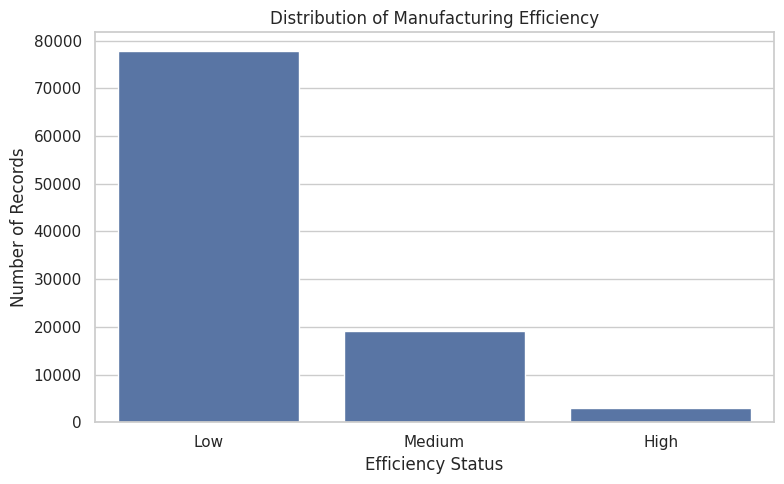

In [ ]:

# STEP 6: Efficiency distribution

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Efficiency_Status",
    order=["Low", "Medium", "High"]
)
plt.title("Distribution of Manufacturing Efficiency")
plt.xlabel("Efficiency Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


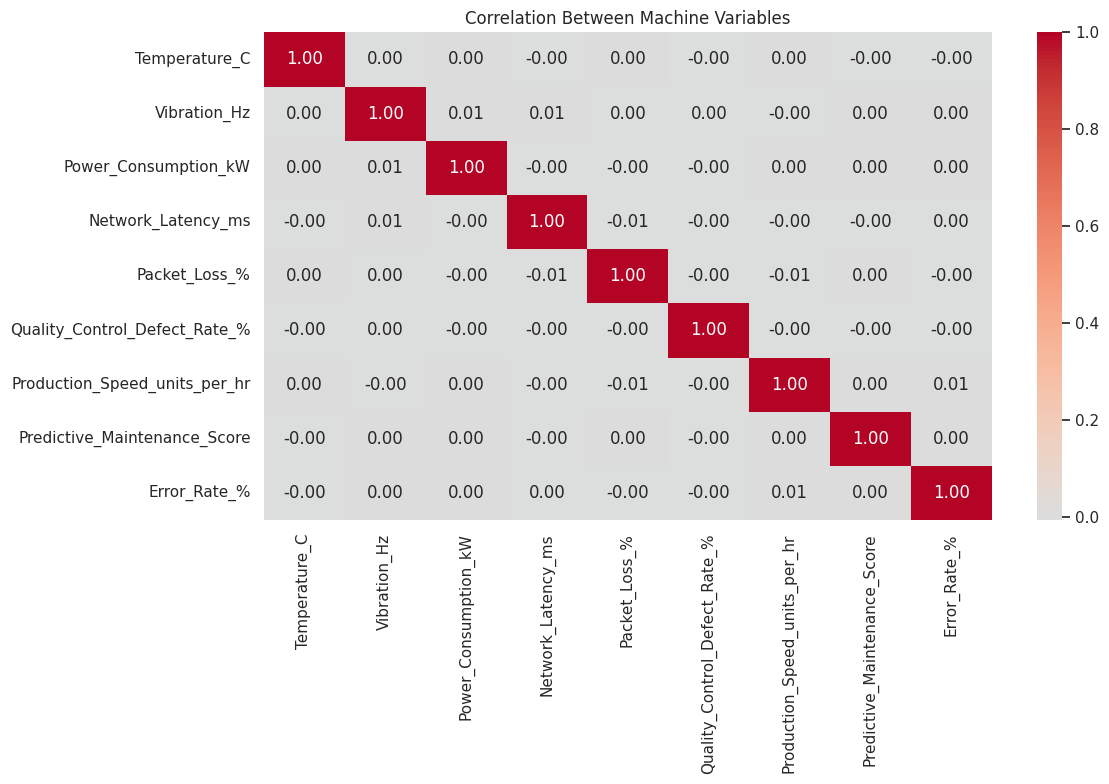

In [ ]:

# STEP 7: Correlation heatmap

plt.figure(figsize=(12, 8))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Machine Variables")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 8: Machine-level analysis

machine_summary = (
    df.groupby("Machine_ID")
    .agg(
        Records=("Machine_ID", "size"),
        Avg_Temperature=("Temperature_C", "mean"),
        Avg_Vibration=("Vibration_Hz", "mean"),
        Avg_Power=("Power_Consumption_kW", "mean"),
        Avg_Network_Latency=("Network_Latency_ms", "mean"),
        Avg_Error_Rate=("Error_Rate_%", "mean"),
        Avg_Maintenance_Score=("Predictive_Maintenance_Score", "mean"),
        Low_Efficiency_Percent=(
            "Efficiency_Status",
            lambda x: (x == "Low").mean() * 100
        )
    )
    .round(2)
    .sort_values("Low_Efficiency_Percent", ascending=False)
)

display(machine_summary.head(15))


,Records,Avg_Temperature,Avg_Vibration,Avg_Power,Avg_Network_Latency,Avg_Error_Rate,Avg_Maintenance_Score,Low_Efficiency_Percent
Machine_ID,,,,,,,,
8,1967,60.17,2.55,5.78,25.43,7.62,0.50,80.43
47,2001,60.33,2.54,5.71,25.41,7.64,0.50,80.06
9,1991,60.28,2.55,5.70,25.31,7.51,0.50,79.46
30,2074,59.54,2.53,5.79,25.48,7.55,0.50,79.27
14,1941,60.30,2.57,5.74,25.77,7.60,0.50,78.98
18,2031,59.88,2.54,5.68,25.65,7.45,0.50,78.83
28,2048,59.78,2.52,5.66,25.74,7.53,0.49,78.76
32,2031,59.31,2.53,5.73,25.50,7.59,0.50,78.73
3,2001,59.41,2.60,5.91,26.01,7.60,0.49,78.66


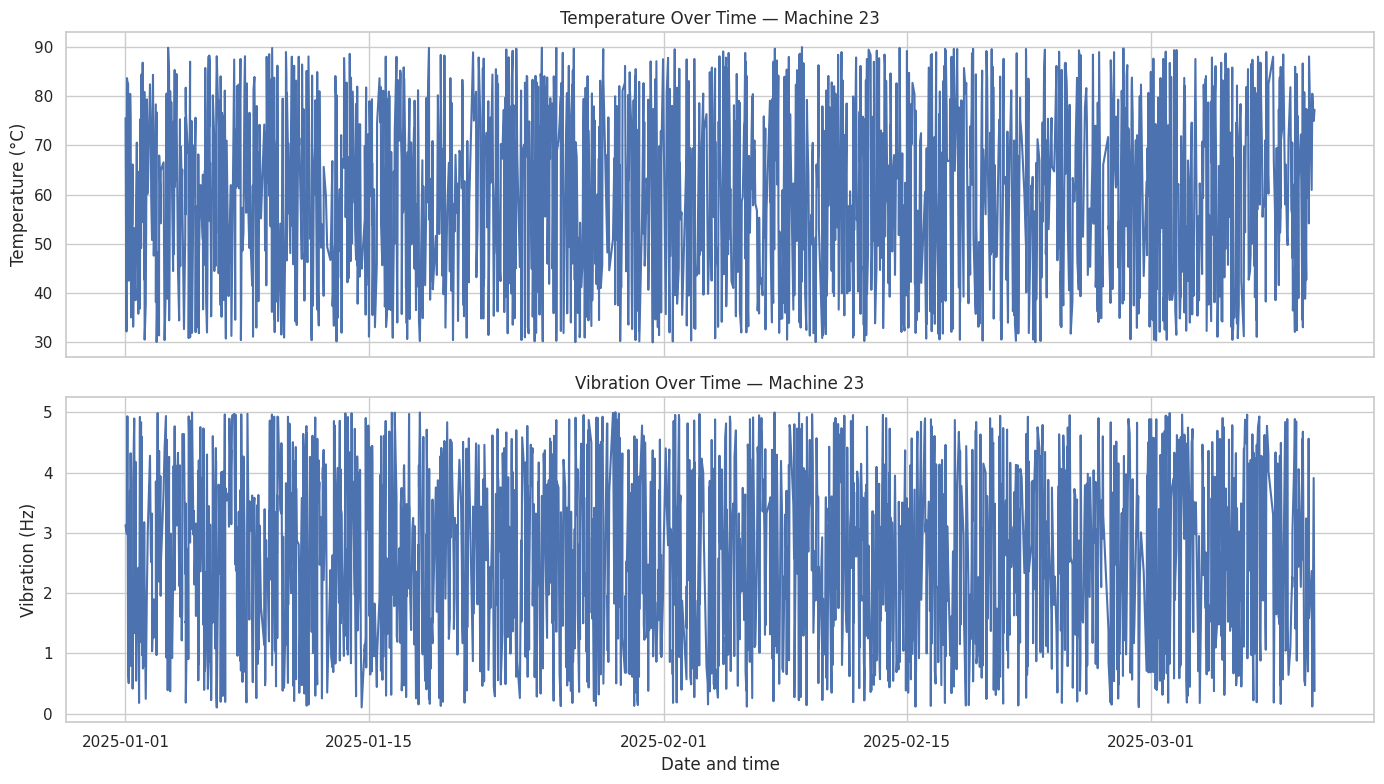

In [ ]:

# STEP 9: Time-series visualization

machine_id = int(df["Machine_ID"].mode().iloc[0])

machine_data = (
    df[df["Machine_ID"] == machine_id]
    .sort_values("DateTime")
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    machine_data["DateTime"],
    machine_data["Temperature_C"]
)
axes[0].set_title(f"Temperature Over Time — Machine {machine_id}")
axes[0].set_ylabel("Temperature (°C)")

axes[1].plot(
    machine_data["DateTime"],
    machine_data["Vibration_Hz"]
)
axes[1].set_title(f"Vibration Over Time — Machine {machine_id}")
axes[1].set_ylabel("Vibration (Hz)")
axes[1].set_xlabel("Date and time")

plt.tight_layout()
plt.show()


In [ ]:

# STEP 10: Prepare machine sensor features

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

feature_columns = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Error_Rate_%"
]

# One-hot encode operating mode
X_numeric = df[feature_columns].copy()

X_mode = pd.get_dummies(
    df["Operation_Mode"],
    prefix="Mode",
    dtype=int
)

X = pd.concat(
    [X_numeric.reset_index(drop=True),
     X_mode.reset_index(drop=True)],
    axis=1
)

print("Features used:", X.columns.tolist())
print("Feature matrix shape:", X.shape)


Features used: ['Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Error_Rate_%', 'Mode_Active', 'Mode_Idle', 'Mode_Maintenance']
Feature matrix shape: (100000, 11)


In [ ]:

# STEP 11: Train Isolation Forest

model = Pipeline([
    ("scaler", StandardScaler()),
    ("isolation_forest", IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X)

# Higher values mean more unusual behavior
df["Anomaly_Score"] = -model.decision_function(X)

# -1 indicates a potential anomaly; 1 indicates an inlier
predictions = model.predict(X)

df["Anomaly_Flag"] = np.where(
    predictions == -1,
    "Potential Anomaly",
    "Normal"
)

print("Model trained successfully.")
print(df["Anomaly_Flag"].value_counts())
display(
    df[
        ["Machine_ID", "DateTime", "Temperature_C",
         "Vibration_Hz", "Anomaly_Score", "Anomaly_Flag"]
    ].head(10)
)


Model trained successfully.
Anomaly_Flag
Normal               95000
Potential Anomaly     5000
Name: count, dtype: int64


,Machine_ID,DateTime,Temperature_C,Vibration_Hz,Anomaly_Score,Anomaly_Flag
0,1,2025-01-01 01:37:00,81.532,3.905,-0.047383,Normal
1,1,2025-01-01 01:42:00,66.906,2.370,-0.127419,Normal
2,1,2025-01-01 02:13:00,67.270,4.467,0.016592,Potential Anomaly
3,1,2025-01-01 02:19:00,72.619,4.942,0.014911,Potential Anomaly
4,1,2025-01-01 03:05:00,58.421,3.656,-0.005707,Normal
5,1,2025-01-01 03:43:00,40.316,1.533,-0.047463,Normal
6,1,2025-01-01 04:24:00,44.727,1.502,-0.082030,Normal
7,1,2025-01-01 04:40:00,67.791,1.355,-0.024045,Normal
8,1,2025-01-01 06:54:00,83.426,4.250,-0.082925,Normal
9,1,2025-01-01 07:46:00,50.180,3.626,-0.082775,Normal


In [ ]:

# STEP 12: Assign relative anomaly-risk levels

low_threshold = df["Anomaly_Score"].quantile(0.80)
high_threshold = df["Anomaly_Score"].quantile(0.95)

df["Maintenance_Risk_Level"] = np.select(
    [
        df["Anomaly_Score"] >= high_threshold,
        df["Anomaly_Score"] >= low_threshold
    ],
    [
        "High",
        "Medium"
    ],
    default="Low"
)

print("Risk level distribution:")
display(df["Maintenance_Risk_Level"].value_counts())

print("\nRisk level percentages:")
display(
    (df["Maintenance_Risk_Level"].value_counts(normalize=True) * 100)
    .round(2)
)


Risk level distribution:


,count
Maintenance_Risk_Level,
Low,80000
Medium,15000
High,5000



Risk level percentages:


,proportion
Maintenance_Risk_Level,
Low,80.0
Medium,15.0
High,5.0


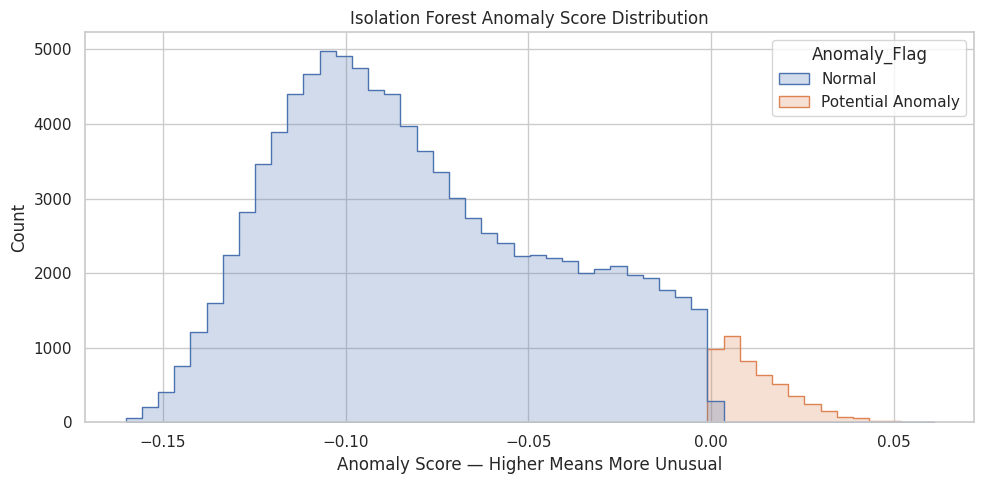

In [ ]:

# STEP 13: Plot anomaly scores

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Anomaly_Score",
    hue="Anomaly_Flag",
    bins=50,
    element="step",
    stat="count",
    common_norm=False
)

plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly Score — Higher Means More Unusual")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 14: List records for maintenance investigation

risk_columns = [
    "DateTime",
    "Machine_ID",
    "Operation_Mode",
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Error_Rate_%",
    "Anomaly_Score",
    "Maintenance_Risk_Level"
]

high_risk_records = (
    df[df["Maintenance_Risk_Level"] == "High"]
    .sort_values("Anomaly_Score", ascending=False)
)

display(high_risk_records[risk_columns].head(30))


,DateTime,Machine_ID,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Error_Rate_%,Anomaly_Score,Maintenance_Risk_Level
67978,2025-03-06 22:13:00,34,Maintenance,88.834,0.123,1.692,32.359,14.771,0.060875,High
95274,2025-02-08 23:18:00,48,Maintenance,37.054,4.832,2.787,49.686,0.533,0.059066,High
62657,2025-01-18 23:36:00,32,Maintenance,30.946,4.803,9.727,37.424,14.769,0.056513,High
83634,2025-02-22 04:35:00,42,Maintenance,82.054,4.929,2.519,5.129,0.741,0.055265,High
24728,2025-01-30 13:38:00,13,Maintenance,34.771,0.650,2.652,39.669,13.926,0.055070,High
74059,2025-01-01 18:00:00,38,Maintenance,74.432,0.554,1.816,49.553,0.525,0.054239,High
27054,2025-02-13 10:42:00,14,Maintenance,35.391,0.736,8.614,49.687,14.617,0.053414,High
21969,2025-01-05 13:19:00,12,Maintenance,87.499,0.357,7.683,49.033,13.295,0.052952,High
84808,2025-01-27 05:55:00,43,Maintenance,73.131,4.568,9.178,48.172,10.636,0.052856,High
78328,2025-01-09 13:59:00,40,Maintenance,62.433,4.901,9.714,46.915,11.756,0.052355,High


In [ ]:

# STEP 15: Save model and project outputs

import joblib

joblib.dump(model, "anomaly_model.joblib")

df.to_csv("processed_manufacturing_data.csv", index=False)

machine_summary.to_csv("machine_summary.csv")

print("Model and processed data saved.")

from google.colab import files

files.download("anomaly_model.joblib")
files.download("processed_manufacturing_data.csv")
files.download("machine_summary.csv")


Model and processed data saved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(
    page_title="Predictive Maintenance | Smart Manufacturing",
    page_icon="🏭",
    layout="wide"
)

st.title("🏭 Predictive Maintenance & Anomaly Detection")
st.caption("6G-Integrated Smart Manufacturing Systems")

@st.cache_data
def load_data():
    data = pd.read_csv("processed_manufacturing_data.csv")
    data["DateTime"] = pd.to_datetime(data["DateTime"], errors="coerce")
    data["Machine_ID"] = data["Machine_ID"].astype(str)
    return data.dropna(subset=["DateTime"])

try:
    df = load_data()
except FileNotFoundError:
    st.error(
        "Dataset not found. Place processed_manufacturing_data.csv "
        "in the same folder as app.py."
    )
    st.stop()

# Sidebar filters
st.sidebar.header("Dashboard Filters")

machine_options = sorted(df["Machine_ID"].unique().tolist())
selected_machines = st.sidebar.multiselect(
    "Select machines",
    machine_options,
    default=machine_options[:min(5, len(machine_options))]
)

risk_options = ["Low", "Medium", "High"]
selected_risks = st.sidebar.multiselect(
    "Maintenance risk",
    risk_options,
    default=risk_options
)

mode_options = sorted(df["Operation_Mode"].dropna().unique().tolist())
selected_modes = st.sidebar.multiselect(
    "Operation mode",
    mode_options,
    default=mode_options
)

start_date = df["DateTime"].min().date()
end_date = df["DateTime"].max().date()

date_range = st.sidebar.date_input(
    "Date range",
    value=(start_date, end_date),
    min_value=start_date,
    max_value=end_date
)

threshold = st.sidebar.slider(
    "Anomaly score alert threshold",
    min_value=float(df["Anomaly_Score"].min()),
    max_value=float(df["Anomaly_Score"].max()),
    value=float(df["Anomaly_Score"].quantile(0.95)),
    step=max(
        float((df["Anomaly_Score"].max() -
               df["Anomaly_Score"].min()) / 1000),
        0.000001
    )
)

# Apply filters
filtered = df.copy()

if selected_machines:
    filtered = filtered[filtered["Machine_ID"].isin(selected_machines)]
else:
    filtered = filtered.iloc[0:0]

if selected_risks:
    filtered = filtered[
        filtered["Maintenance_Risk_Level"].isin(selected_risks)
    ]
else:
    filtered = filtered.iloc[0:0]

if selected_modes:
    filtered = filtered[
        filtered["Operation_Mode"].isin(selected_modes)
    ]
else:
    filtered = filtered.iloc[0:0]

if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    filtered = filtered[
        (filtered["DateTime"].dt.date >= date_range[0]) &
        (filtered["DateTime"].dt.date <= date_range[1])
    ]

if filtered.empty:
    st.warning("No records match these filters. Change your selections.")
    st.stop()

# Overview metrics
st.header("1. Predictive Maintenance Overview")

c1, c2, c3, c4 = st.columns(4)

c1.metric("Records", f"{len(filtered):,}")
c2.metric("Machines", filtered["Machine_ID"].nunique())
c3.metric(
    "High-risk records",
    f"{(filtered['Maintenance_Risk_Level'] == 'High').sum():,}"
)
c4.metric(
    "Potential anomalies",
    f"{(filtered['Anomaly_Flag'] == 'Potential Anomaly').sum():,}"
)

left, right = st.columns(2)

risk_counts = (
    filtered["Maintenance_Risk_Level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Risk")
    .reset_index(name="Records")
)

with left:
    fig = px.bar(
        risk_counts,
        x="Risk",
        y="Records",
        color="Risk",
        title="Risk Distribution",
        category_orders={"Risk": ["Low", "Medium", "High"]}
    )
    st.plotly_chart(fig, use_container_width=True)

with right:
    mode_counts = (
        filtered["Operation_Mode"]
        .value_counts()
        .rename_axis("Operation Mode")
        .reset_index(name="Records")
    )
    fig = px.pie(
        mode_counts,
        names="Operation Mode",
        values="Records",
        title="Operating Mode Distribution"
    )
    st.plotly_chart(fig, use_container_width=True)

# Machine anomaly analysis
st.header("2. Machine Anomaly Dashboard")

machine = st.selectbox(
    "Choose a machine for detailed analysis",
    sorted(filtered["Machine_ID"].unique())
)

machine_df = (
    filtered[filtered["Machine_ID"] == machine]
    .sort_values("DateTime")
)

sensor_options = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Error_Rate_%"
]

sensor = st.selectbox("Select sensor", sensor_options)

fig = px.line(
    machine_df,
    x="DateTime",
    y=sensor,
    title=f"{sensor} over time — Machine {machine}",
    markers=False
)
st.plotly_chart(fig, use_container_width=True)

fig = px.scatter(
    machine_df,
    x="DateTime",
    y="Anomaly_Score",
    color="Anomaly_Flag",
    hover_data=["Temperature_C", "Vibration_Hz", "Operation_Mode"],
    title="Anomaly Score over Time"
)
fig.add_hline(
    y=threshold,
    line_dash="dash",
    annotation_text="Selected alert threshold"
)
st.plotly_chart(fig, use_container_width=True)

# Maintenance alert panel
st.header("3. Maintenance Alert Panel")

alerts = filtered[
    (filtered["Anomaly_Score"] >= threshold) |
    (filtered["Maintenance_Risk_Level"] == "High")
].copy()

alert_columns = [
    "DateTime", "Machine_ID", "Operation_Mode",
    "Temperature_C", "Vibration_Hz",
    "Power_Consumption_kW", "Error_Rate_%",
    "Anomaly_Score", "Maintenance_Risk_Level"
]

alerts = alerts.sort_values("Anomaly_Score", ascending=False)

st.write(f"Records requiring investigation: {len(alerts):,}")
st.dataframe(
    alerts[alert_columns].head(500),
    use_container_width=True,
    hide_index=True
)

st.download_button(
    "Download alert records as CSV",
    data=alerts[alert_columns].to_csv(index=False).encode("utf-8"),
    file_name="maintenance_alerts.csv",
    mime="text/csv"
)

# Historical analysis
st.header("4. Historical Risk Analysis")

history = (
    filtered.set_index("DateTime")
    .groupby("Maintenance_Risk_Level")
    .resample("D")
    .size()
    .rename("Records")
    .reset_index()
)

fig = px.line(
    history,
    x="DateTime",
    y="Records",
    color="Maintenance_Risk_Level",
    title="Daily Records by Risk Level"
)
st.plotly_chart(fig, use_container_width=True)

daily_sensor = (
    filtered.set_index("DateTime")
    .resample("D")[["Temperature_C", "Vibration_Hz"]]
    .mean()
    .reset_index()
)

fig = px.line(
    daily_sensor,
    x="DateTime",
    y=["Temperature_C", "Vibration_Hz"],
    title="Daily Average Sensor Trends"
)
st.plotly_chart(fig, use_container_width=True)

# Data download
st.header("Dataset Export")

st.download_button(
    "Download filtered dataset",
    data=filtered.to_csv(index=False).encode("utf-8"),
    file_name="filtered_manufacturing_data.csv",
    mime="text/csv"
)

st.caption(
    "Risk categories are relative anomaly indicators, not calibrated "
    "failure probabilities. Verify alerts against machine specifications "
    "and maintenance records before taking action."
)


Writing app.py


In [ ]:

%%writefile requirements.txt
streamlit
pandas
numpy
plotly
scikit-learn
joblib



Writing requirements.txt


In [ ]:

%%writefile README.md
# Predictive Maintenance and Anomaly Detection

A data science project for 6G-integrated smart manufacturing.

## Features
- Manufacturing sensor data analysis
- Isolation Forest anomaly detection
- Relative maintenance risk categories
- Machine-level sensor visualizations
- Maintenance alert table
- Historical trend analysis
- CSV downloads

## Requirements
Python 3.10 or newer

## Run locally
1. Install dependencies:
   pip install -r requirements.txt

2. Place processed_manufacturing_data.csv next to app.py.

3. Launch the dashboard:
   streamlit run app.py

## Important
Risk levels represent relative anomaly scores, not validated
probabilities of equipment failure.


Writing README.md


In [ ]:

# STEP 19: Download application files

from google.colab import files

files.download("app.py")
files.download("requirements.txt")
files.download("README.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>